In [1]:
# IMPORT LIBRARY
from pathlib import Path
import polars as pl
import duckdb
import plotly.express as px
import plotly.graph_objects as go

# MENENTUKAN FOLDER PROYEK
PROJECT_DIR = Path("/home/jovyan/work")

# LOKASI DATA HASIL CLEANING
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
CLEAN_PATH = PROCESSED_DIR / "flood_dataset_cleaned.parquet"

# MEMERIKSA DATASET
print("=== PERSIAPAN EDA ===")
print("Lokasi dataset:", CLEAN_PATH)

if not CLEAN_PATH.exists():
    raise FileNotFoundError(
        f"Dataset hasil cleaning tidak ditemukan: {CLEAN_PATH}"
    )

# MEMBACA DATASET
df = pl.read_parquet(CLEAN_PATH)

print("\n=== INFORMASI DATASET EDA ===")
print(f"Jumlah baris : {df.height:,}")
print(f"Jumlah kolom : {df.width}")
print(f"Ukuran file  : {CLEAN_PATH.stat().st_size / (1024**2):.2f} MB")

print("\nDataset berhasil dimuat.")

=== PERSIAPAN EDA ===
Lokasi dataset: /home/jovyan/work/data/processed/flood_dataset_cleaned.parquet

=== INFORMASI DATASET EDA ===
Jumlah baris : 1,152,432
Jumlah kolom : 13
Ukuran file  : 14.53 MB

Dataset berhasil dimuat.


=== TREN LABEL BANJIR PER TAHUN ===
shape: (10, 3)
┌──────┬──────────────────┬─────────────────────────┐
│ year ┆ jumlah_observasi ┆ persentase_label_banjir │
│ ---  ┆ ---              ┆ ---                     │
│ i32  ┆ u32              ┆ f64                     │
╞══════╪══════════════════╪═════════════════════════╡
│ 2015 ┆ 106848           ┆ 6.194781                │
│ 2016 ┆ 116388           ┆ 13.106162               │
│ 2017 ┆ 116070           ┆ 6.856207                │
│ 2018 ┆ 116070           ┆ 4.151805                │
│ 2019 ┆ 116070           ┆ 4.893599                │
│ 2020 ┆ 116388           ┆ 11.850019               │
│ 2021 ┆ 116070           ┆ 11.961747               │
│ 2022 ┆ 116070           ┆ 3.672784                │
│ 2023 ┆ 116070           ┆ 3.753769                │
│ 2024 ┆ 116388           ┆ 6.602914                │
└──────┴──────────────────┴─────────────────────────┘


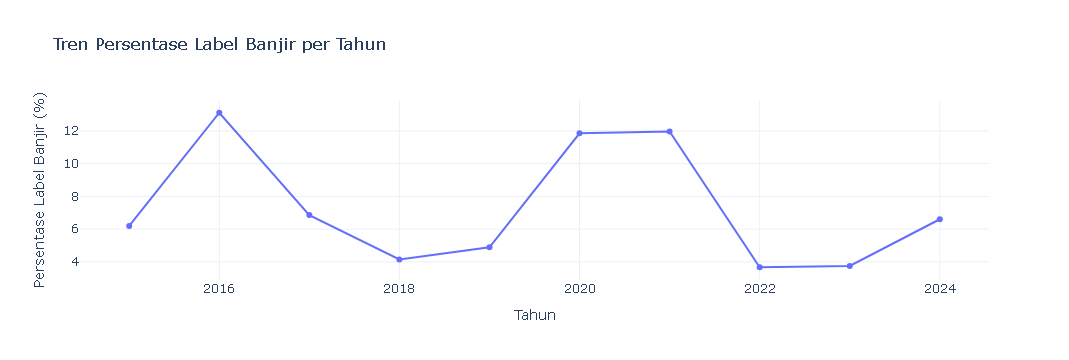

In [2]:
# ANALISIS TEMPORAL: TREN RISIKO BANJIR PER TAHUN

tren_tahunan = (
    df.group_by("year")
    .agg(
        pl.len().alias("jumlah_observasi"),
        (
            pl.col("flood_label").mean() * 100
        ).alias("persentase_label_banjir")
    )
    .sort("year")
)

print("=== TREN LABEL BANJIR PER TAHUN ===")
print(tren_tahunan)

# VISUALISASI 1
fig1 = px.line(
    tren_tahunan.to_pandas(),
    x="year",
    y="persentase_label_banjir",
    markers=True,
    title="Tren Persentase Label Banjir per Tahun",
    labels={
        "year": "Tahun",
        "persentase_label_banjir": "Persentase Label Banjir (%)"
    }
)

fig1.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig1.show()

=== DISTRIBUSI LABEL BANJIR PER BULAN ===
shape: (12, 3)
┌───────┬──────────────────┬─────────────────────────┐
│ month ┆ jumlah_observasi ┆ persentase_label_banjir │
│ ---   ┆ ---              ┆ ---                     │
│ i32   ┆ u32              ┆ f64                     │
╞═══════╪══════════════════╪═════════════════════════╡
│ 1     ┆ 89358            ┆ 13.866694               │
│ 2     ┆ 89994            ┆ 33.506678               │
│ 3     ┆ 98580            ┆ 16.338                  │
│ 4     ┆ 95400            ┆ 4.856394                │
│ 5     ┆ 98580            ┆ 0.637046                │
│ …     ┆ …                ┆ …                       │
│ 8     ┆ 98580            ┆ 0.124772                │
│ 9     ┆ 95400            ┆ 0.469602                │
│ 10    ┆ 98580            ┆ 4.08805                 │
│ 11    ┆ 95400            ┆ 6.39413                 │
│ 12    ┆ 98580            ┆ 9.511057                │
└───────┴──────────────────┴─────────────────────────┘


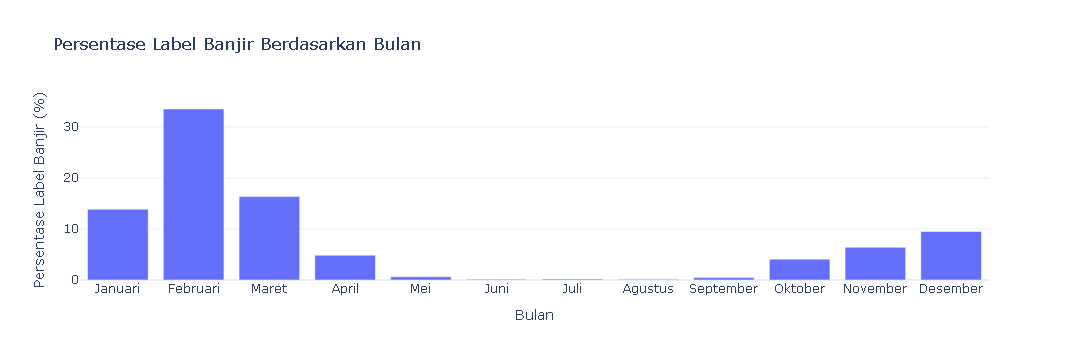

In [3]:
# ANALISIS TEMPORAL: POLA BANJIR BERDASARKAN BULAN

tren_bulanan = (
    df.group_by("month")
    .agg(
        pl.len().alias("jumlah_observasi"),
        (
            pl.col("flood_label").mean() * 100
        ).alias("persentase_label_banjir")
    )
    .sort("month")
)

print("=== DISTRIBUSI LABEL BANJIR PER BULAN ===")
print(tren_bulanan)

# VISUALISASI 2
nama_bulan = [
    "Januari", "Februari", "Maret",
    "April", "Mei", "Juni",
    "Juli", "Agustus", "September",
    "Oktober", "November", "Desember"
]

data_bulanan = tren_bulanan.to_pandas()
data_bulanan["nama_bulan"] = data_bulanan["month"].map(
    lambda x: nama_bulan[x - 1]
)

fig2 = px.bar(
    data_bulanan,
    x="nama_bulan",
    y="persentase_label_banjir",
    title="Persentase Label Banjir Berdasarkan Bulan",
    labels={
        "nama_bulan": "Bulan",
        "persentase_label_banjir": "Persentase Label Banjir (%)"
    },
    hover_data=["jumlah_observasi"]
)

fig2.update_layout(
    template="plotly_white",
    xaxis_title="Bulan",
    yaxis_title="Persentase Label Banjir (%)"
)

fig2.show()

=== 10 KECAMATAN DENGAN PERSENTASE LABEL BANJIR TERTINGGI ===
shape: (10, 4)
┌────────────────┬──────────────────┬─────────────────────┬─────────────────────────┐
│ district_id    ┆ jumlah_observasi ┆ jumlah_label_banjir ┆ persentase_label_banjir │
│ ---            ┆ ---              ┆ ---                 ┆ ---                     │
│ str            ┆ u32              ┆ f64                 ┆ f64                     │
╞════════════════╪══════════════════╪═════════════════════╪═════════════════════════╡
│ IDN.7.5.7_1    ┆ 3624             ┆ 374.0               ┆ 10.320088               │
│ IDN.7.5.2_1    ┆ 3624             ┆ 362.0               ┆ 9.988962                │
│ IDN.10.17.6_1  ┆ 3624             ┆ 356.0               ┆ 9.8234                  │
│ IDN.10.22.16_1 ┆ 3624             ┆ 349.0               ┆ 9.630243                │
│ IDN.10.22.17_1 ┆ 3624             ┆ 349.0               ┆ 9.630243                │
│ IDN.7.5.3_1    ┆ 3624             ┆ 344.0               ┆ 9.4

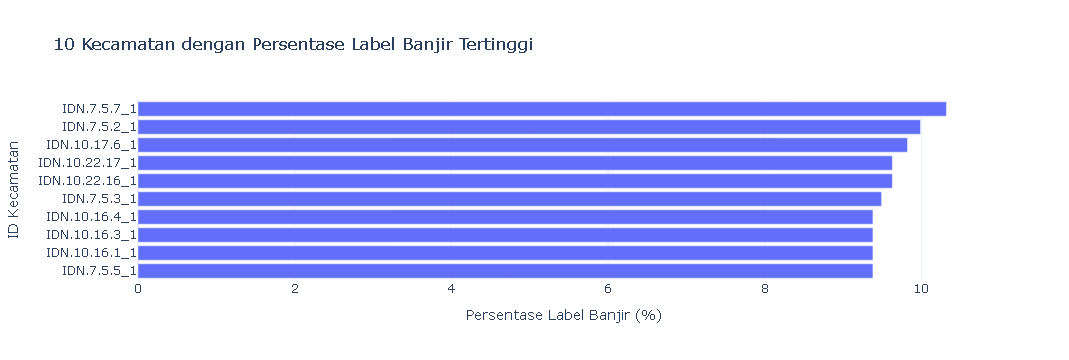

In [4]:
# ANALISIS SPASIAL BERDASARKAN KECAMATAN

risiko_wilayah = (
    df.group_by("district_id")
    .agg(
        pl.len().alias("jumlah_observasi"),
        pl.col("flood_label").sum().alias("jumlah_label_banjir"),
        (
            pl.col("flood_label").mean() * 100
        ).alias("persentase_label_banjir")
    )
    .sort(
        "persentase_label_banjir",
        descending=True
    )
)

# MENGAMBIL 10 KECAMATAN TERTINGGI
top_10_wilayah = risiko_wilayah.head(10)

print("=== 10 KECAMATAN DENGAN PERSENTASE LABEL BANJIR TERTINGGI ===")
print(top_10_wilayah)

# VISUALISASI 3
fig3 = px.bar(
    top_10_wilayah.to_pandas(),
    x="persentase_label_banjir",
    y="district_id",
    orientation="h",
    title="10 Kecamatan dengan Persentase Label Banjir Tertinggi",
    labels={
        "district_id": "ID Kecamatan",
        "persentase_label_banjir": "Persentase Label Banjir (%)"
    },
    hover_data=[
        "jumlah_observasi",
        "jumlah_label_banjir"
    ]
)

fig3.update_layout(
    template="plotly_white",
    yaxis={"categoryorder": "total ascending"}
)

fig3.show()

=== PERBANDINGAN PESISIR DAN NONPESISIR ===
shape: (2, 5)
┌─────────┬──────────────────┬─────────────────────┬─────────────────────────┬──────────────────┐
│ coastal ┆ jumlah_observasi ┆ jumlah_label_banjir ┆ persentase_label_banjir ┆ kategori_wilayah │
│ ---     ┆ ---              ┆ ---                 ┆ ---                     ┆ ---              │
│ i64     ┆ u32              ┆ f64                 ┆ f64                     ┆ str              │
╞═════════╪══════════════════╪═════════════════════╪═════════════════════════╪══════════════════╡
│ 0       ┆ 115968           ┆ 8824.0              ┆ 7.608996                ┆ Nonpesisir       │
│ 1       ┆ 1036464          ┆ 75487.0             ┆ 7.283128                ┆ Pesisir          │
└─────────┴──────────────────┴─────────────────────┴─────────────────────────┴──────────────────┘


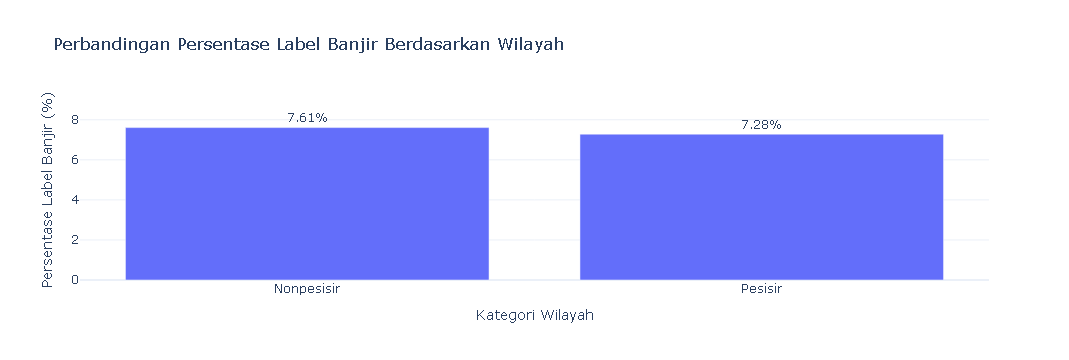

In [5]:
# ANALISIS SPASIAL: WILAYAH PESISIR DAN NONPESISIR

analisis_pesisir = (
    df.group_by("coastal")
    .agg(
        pl.len().alias("jumlah_observasi"),
        pl.col("flood_label").sum().alias("jumlah_label_banjir"),
        (
            pl.col("flood_label").mean() * 100
        ).alias("persentase_label_banjir")
    )
    .sort("coastal")
)

# MEMBERIKAN NAMA KATEGORI WILAYAH
analisis_pesisir = analisis_pesisir.with_columns(
    pl.when(pl.col("coastal") == 0)
    .then(pl.lit("Nonpesisir"))
    .when(pl.col("coastal") == 1)
    .then(pl.lit("Pesisir"))
    .alias("kategori_wilayah")
)

print("=== PERBANDINGAN PESISIR DAN NONPESISIR ===")
print(analisis_pesisir)

# VISUALISASI 4
fig4 = px.bar(
    analisis_pesisir.to_pandas(),
    x="kategori_wilayah",
    y="persentase_label_banjir",
    text="persentase_label_banjir",
    title="Perbandingan Persentase Label Banjir Berdasarkan Wilayah",
    labels={
        "kategori_wilayah": "Kategori Wilayah",
        "persentase_label_banjir": "Persentase Label Banjir (%)"
    },
    hover_data=[
        "jumlah_observasi",
        "jumlah_label_banjir"
    ]
)

fig4.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig4.update_layout(
    template="plotly_white",
    yaxis_title="Persentase Label Banjir (%)"
)

fig4.show()

=== PERBANDINGAN CURAH HUJAN BERDASARKAN LABEL BANJIR ===
shape: (2, 6)
┌─────────────┬──────────────────┬─────────────────┬──────────────┬─────┬──────┐
│ flood_label ┆ jumlah_observasi ┆ rata_rata_hujan ┆ median_hujan ┆ Q1  ┆ Q3   │
│ ---         ┆ ---              ┆ ---             ┆ ---          ┆ --- ┆ ---  │
│ f64         ┆ u32              ┆ f64             ┆ f64          ┆ f64 ┆ f64  │
╞═════════════╪══════════════════╪═════════════════╪══════════════╪═════╪══════╡
│ 0.0         ┆ 1068121          ┆ 5.983543        ┆ 2.4          ┆ 0.2 ┆ 8.6  │
│ 1.0         ┆ 84311            ┆ 17.060132       ┆ 13.4         ┆ 7.3 ┆ 21.7 │
└─────────────┴──────────────────┴─────────────────┴──────────────┴─────┴──────┘


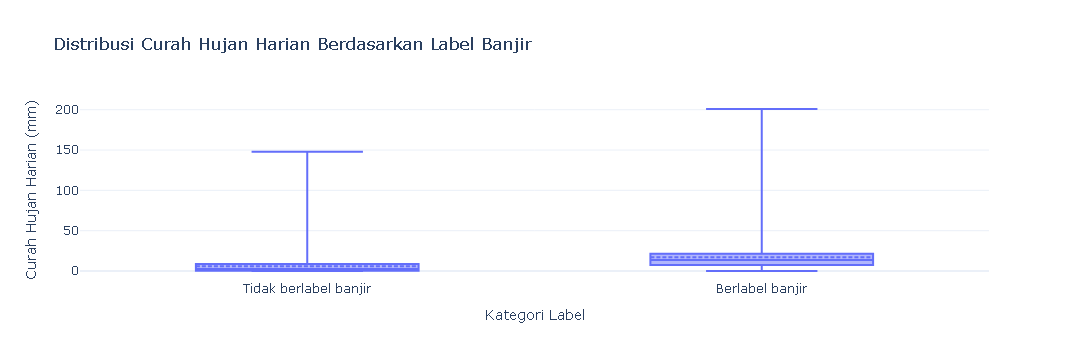

In [6]:
# ANALISIS HUBUNGAN CURAH HUJAN DENGAN LABEL BANJIR

perbandingan_hujan = (
    df.group_by("flood_label")
    .agg(
        pl.len().alias("jumlah_observasi"),
        pl.col("rain_1d").mean().alias("rata_rata_hujan"),
        pl.col("rain_1d").median().alias("median_hujan"),
        pl.col("rain_1d").quantile(0.25).alias("Q1"),
        pl.col("rain_1d").quantile(0.75).alias("Q3")
    )
    .sort("flood_label")
)

print("=== PERBANDINGAN CURAH HUJAN BERDASARKAN LABEL BANJIR ===")
print(perbandingan_hujan)

# MENGAMBIL SAMPEL UNTUK VISUALISASI
# Statistik di atas tetap dihitung dari seluruh dataset.

sampel_hujan = pl.concat([
    df.filter(pl.col("flood_label") == 0)
      .sample(n=5000, seed=42),

    df.filter(pl.col("flood_label") == 1)
      .sample(n=5000, seed=42)
])

data_boxplot = sampel_hujan.select(
    "flood_label",
    "rain_1d"
).to_pandas()

data_boxplot["kategori_label"] = data_boxplot[
    "flood_label"
].map({
    0.0: "Tidak berlabel banjir",
    1.0: "Berlabel banjir"
})

# VISUALISASI 5
fig5 = px.box(
    data_boxplot,
    x="kategori_label",
    y="rain_1d",
    points=False,
    title="Distribusi Curah Hujan Harian Berdasarkan Label Banjir",
    labels={
        "kategori_label": "Kategori Label",
        "rain_1d": "Curah Hujan Harian (mm)"
    }
)

fig5.update_traces(boxmean=True)

fig5.update_layout(
    template="plotly_white",
    yaxis_title="Curah Hujan Harian (mm)"
)

fig5.show()

=== POLA LABEL BANJIR BERDASARKAN TAHUN DAN BULAN ===
shape: (120, 3)
┌──────┬───────┬─────────────────────────┐
│ year ┆ month ┆ persentase_label_banjir │
│ ---  ┆ ---   ┆ ---                     │
│ i32  ┆ i32   ┆ f64                     │
╞══════╪═══════╪═════════════════════════╡
│ 2015 ┆ 1     ┆ 54.716981               │
│ 2015 ┆ 2     ┆ 49.067835               │
│ 2015 ┆ 3     ┆ 6.59363                 │
│ 2015 ┆ 4     ┆ 4.863732                │
│ 2015 ┆ 5     ┆ 0.294177                │
│ …    ┆ …     ┆ …                       │
│ 2024 ┆ 8     ┆ 0.0                     │
│ 2024 ┆ 9     ┆ 0.377358                │
│ 2024 ┆ 10    ┆ 0.0                     │
│ 2024 ┆ 11    ┆ 1.205451                │
│ 2024 ┆ 12    ┆ 17.894096               │
└──────┴───────┴─────────────────────────┘


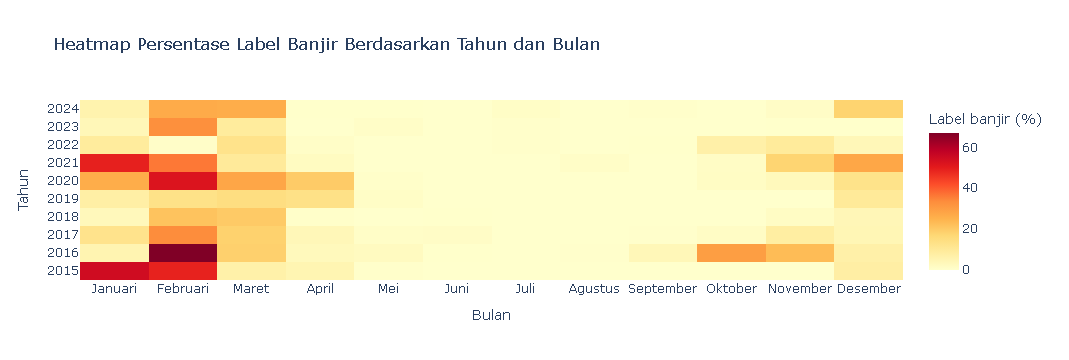

In [7]:
# ANALISIS TEMPORAL: POLA BANJIR BERDASARKAN TAHUN DAN BULAN

heatmap_data = (
    df.group_by(["year", "month"])
    .agg(
        (
            pl.col("flood_label").mean() * 100
        ).alias("persentase_label_banjir")
    )
    .sort(["year", "month"])
)

print("=== POLA LABEL BANJIR BERDASARKAN TAHUN DAN BULAN ===")
print(heatmap_data)

# MENGUBAH DATA KE FORMAT HEATMAP
data_pivot = (
    heatmap_data.to_pandas()
    .pivot(
        index="year",
        columns="month",
        values="persentase_label_banjir"
    )
)

nama_bulan = [
    "Januari", "Februari", "Maret",
    "April", "Mei", "Juni",
    "Juli", "Agustus", "September",
    "Oktober", "November", "Desember"
]

# VISUALISASI 6
fig6 = go.Figure(
    data=go.Heatmap(
        z=data_pivot.values,
        x=nama_bulan,
        y=data_pivot.index.astype(str),
        colorscale="YlOrRd",
        colorbar=dict(
            title="Label banjir (%)"
        ),
        hovertemplate=(
            "Tahun: %{y}<br>"
            "Bulan: %{x}<br>"
            "Persentase label banjir: %{z:.2f}%"
            "<extra></extra>"
        )
    )
)

fig6.update_layout(
    title="Heatmap Persentase Label Banjir Berdasarkan Tahun dan Bulan",
    xaxis_title="Bulan",
    yaxis_title="Tahun",
    template="plotly_white"
)

fig6.show()

In [8]:
# RINGKASAN 5 INSIGHT UTAMA

# 1. Tahun dengan persentase label banjir tertinggi
tahun_tertinggi = (
    tren_tahunan
    .sort("persentase_label_banjir", descending=True)
    .row(0, named=True)
)

# 2. Bulan dengan persentase label banjir tertinggi
bulan_tertinggi = (
    tren_bulanan
    .sort("persentase_label_banjir", descending=True)
    .row(0, named=True)
)

nama_bulan = {
    1: "Januari", 2: "Februari", 3: "Maret",
    4: "April", 5: "Mei", 6: "Juni",
    7: "Juli", 8: "Agustus", 9: "September",
    10: "Oktober", 11: "November", 12: "Desember"
}

# 3. Kecamatan dengan persentase tertinggi
wilayah_tertinggi = risiko_wilayah.row(0, named=True)

# 4. Perbandingan pesisir dan nonpesisir
nonpesisir = analisis_pesisir.filter(
    pl.col("coastal") == 0
).row(0, named=True)

pesisir = analisis_pesisir.filter(
    pl.col("coastal") == 1
).row(0, named=True)

# 5. Perbandingan rata-rata curah hujan
tanpa_label = perbandingan_hujan.filter(
    pl.col("flood_label") == 0
).row(0, named=True)

dengan_label = perbandingan_hujan.filter(
    pl.col("flood_label") == 1
).row(0, named=True)

rasio_hujan = (
    dengan_label["rata_rata_hujan"] /
    tanpa_label["rata_rata_hujan"]
)

print("========== 5 INSIGHT UTAMA ==========")

print("\n1. TAHUN DENGAN LABEL BANJIR TERTINGGI")
print(
    f"Tahun {tahun_tertinggi['year']} memiliki "
    f"persentase label banjir tertinggi sebesar "
    f"{tahun_tertinggi['persentase_label_banjir']:.2f}%."
)

print("\n2. BULAN DENGAN LABEL BANJIR TERTINGGI")
print(
    f"{nama_bulan[bulan_tertinggi['month']]} memiliki "
    f"persentase label banjir tertinggi sebesar "
    f"{bulan_tertinggi['persentase_label_banjir']:.2f}%."
)

print("\n3. KECAMATAN DENGAN LABEL BANJIR TERTINGGI")
print(
    f"Kecamatan {wilayah_tertinggi['district_id']} memiliki "
    f"persentase sebesar "
    f"{wilayah_tertinggi['persentase_label_banjir']:.2f}%."
)

print("\n4. PERBANDINGAN WILAYAH PESISIR")
print(
    f"Nonpesisir: {nonpesisir['persentase_label_banjir']:.2f}%, "
    f"Pesisir: {pesisir['persentase_label_banjir']:.2f}%."
)

print("\n5. HUBUNGAN CURAH HUJAN DENGAN LABEL BANJIR")
print(
    f"Rata-rata curah hujan pada observasi berlabel banjir "
    f"{dengan_label['rata_rata_hujan']:.2f} mm, "
    f"sedangkan observasi tanpa label banjir "
    f"{tanpa_label['rata_rata_hujan']:.2f} mm."
)

print(f"Perbandingan rata-rata: {rasio_hujan:.2f} kali.")

========== 5 INSIGHT UTAMA ==========

1. TAHUN DENGAN LABEL BANJIR TERTINGGI
Tahun 2016 memiliki persentase label banjir tertinggi sebesar 13.11%.

2. BULAN DENGAN LABEL BANJIR TERTINGGI
Februari memiliki persentase label banjir tertinggi sebesar 33.51%.

3. KECAMATAN DENGAN LABEL BANJIR TERTINGGI
Kecamatan IDN.7.5.7_1 memiliki persentase sebesar 10.32%.

4. PERBANDINGAN WILAYAH PESISIR
Nonpesisir: 7.61%, Pesisir: 7.28%.

5. HUBUNGAN CURAH HUJAN DENGAN LABEL BANJIR
Rata-rata curah hujan pada observasi berlabel banjir 17.06 mm, sedangkan observasi tanpa label banjir 5.98 mm.
Perbandingan rata-rata: 2.85 kali.


In [9]:
# MENYIAPKAN FOLDER OUTPUT EDA

OUTPUT_DIR = PROJECT_DIR / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "visualizations"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# MENYIMPAN TABEL HASIL ANALISIS

hasil_tabel = {
    "tren_tahunan": tren_tahunan,
    "tren_bulanan": tren_bulanan,
    "risiko_per_kecamatan": risiko_wilayah,
    "perbandingan_pesisir": analisis_pesisir,
    "perbandingan_curah_hujan": perbandingan_hujan,
    "heatmap_tahun_bulan": heatmap_data
}

for nama, tabel in hasil_tabel.items():
    tabel.write_csv(TABLE_DIR / f"{nama}.csv")


# MENYIMPAN 6 VISUALISASI INTERAKTIF

hasil_grafik = {
    "01_tren_banjir_tahunan": fig1,
    "02_tren_banjir_bulanan": fig2,
    "03_top_10_kecamatan": fig3,
    "04_perbandingan_pesisir": fig4,
    "05_curah_hujan_dan_banjir": fig5,
    "06_heatmap_tahun_bulan": fig6
}

for nama, grafik in hasil_grafik.items():
    grafik.write_html(
        FIGURE_DIR / f"{nama}.html",
        include_plotlyjs="directory"
    )


# MENYIMPAN 5 INSIGHT UTAMA

insight_text = f"""
# Lima Insight Utama SIAGA Pantura

1. Tahun {tahun_tertinggi['year']} memiliki persentase
   label banjir tertinggi sebesar
   {tahun_tertinggi['persentase_label_banjir']:.2f}%.

2. Bulan {nama_bulan[bulan_tertinggi['month']]}
   memiliki persentase label banjir tertinggi sebesar
   {bulan_tertinggi['persentase_label_banjir']:.2f}%.

3. Kecamatan {wilayah_tertinggi['district_id']}
   memiliki persentase label banjir sebesar
   {wilayah_tertinggi['persentase_label_banjir']:.2f}%.

4. Persentase label banjir wilayah nonpesisir sebesar
   {nonpesisir['persentase_label_banjir']:.2f}%, sedangkan
   wilayah pesisir sebesar
   {pesisir['persentase_label_banjir']:.2f}%.

5. Rata-rata curah hujan observasi berlabel banjir sebesar
   {dengan_label['rata_rata_hujan']:.2f} mm, sedangkan
   observasi tanpa label banjir sebesar
   {tanpa_label['rata_rata_hujan']:.2f} mm.

Catatan:
Temuan menunjukkan pola dan hubungan statistik dalam dataset,
bukan hubungan sebab-akibat.
"""

(OUTPUT_DIR / "insights_utama.md").write_text(
    insight_text,
    encoding="utf-8"
)


# RINGKASAN PENYIMPANAN

print("=== PENYIMPANAN HASIL EDA ===")
print(f"Jumlah tabel tersimpan  : {len(hasil_tabel)}")
print(f"Jumlah grafik tersimpan : {len(hasil_grafik)}")
print(f"Folder tabel            : {TABLE_DIR}")
print(f"Folder visualisasi      : {FIGURE_DIR}")
print(f"File insight            : {(OUTPUT_DIR / 'insights_utama.md').exists()}")

print("\nEDA berhasil disimpan.")

=== PENYIMPANAN HASIL EDA ===
Jumlah tabel tersimpan  : 6
Jumlah grafik tersimpan : 6
Folder tabel            : /home/jovyan/work/outputs/tables
Folder visualisasi      : /home/jovyan/work/outputs/visualizations
File insight            : True

EDA berhasil disimpan.
